# Model Selection and Ensemble Methods for Equity Returns


This notebook extends the baseline ML toolkit with three advanced topics applied to the same weekly MSCI equity-index dataset (35 international indices, 2016–2020):

1. **Hyperparameter Optimization** — validation curves, grid search, random search, and final test-set confirmation.
2. **Bias–Variance Tradeoff** — empirical decomposition via bootstrap resampling, learning curves, and regularization as a continuous bias–variance dial.
3. **Ensemble Learning** — bagging, random forests, gradient boosting, and a stacked meta-learner that combines the individual models from the baseline analysis.

The primary prediction task throughout is the "big-move" classification: will next week's Luxembourg index (LUXXX) return move by more than 2.5% in absolute value?

## Imports and loading of the dataset (used by all three issues)

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     RandomizedSearchCV, validation_curve,
                                     learning_curve, cross_val_score)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              StackingClassifier)
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, mean_squared_error)
from scipy.stats import loguniform

warnings.filterwarnings("ignore")
RNG = 0

# Weekly MSCI international equity indices, 2016-2020.
# utf-8-sig removes the BOM character that Excel adds in front of "Date"
data_df = pd.read_csv("../../data/weekly_msci_indices.csv", encoding="utf-8-sig")
data_df["Date"] = pd.to_datetime(data_df["Date"], format="%d-%b-%y")
data_df = data_df.set_index("Date")
print("Dataset shape:", data_df.shape)

Dataset shape: (252, 35)


## Construction of the two prediction problems (identical to )

- Classification: does next week's LUXXX return exceed ±2.5%?
  (same shuffled 80/20 split as baseline analysis Categories 4–6, kept so that all
  baseline analysis results remain directly comparable with the baseline analysis baselines).
- Regression: next week's LUXXX return from the other 34 indices
  (used in Issue 2 for the bias–variance decomposition).

In [2]:
rets = data_df.pct_change().dropna()
rets["Fwd_Return"] = rets["LUXXX"].shift(-1)
rets = rets.dropna()

features = [c for c in rets.columns if c not in ["Fwd_Return", "LUXXX"]]

# --- classification problem ---
y_clf = np.where(rets["Fwd_Return"].abs() > 0.025, 1, 0)
X_clf = rets[features]
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RNG)

# scaled copies for the SVM and the LDA
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# --- regression problem (time-ordered split, as in  Cat. 1 and 7) ---
X_reg = rets[features].values
y_reg = rets["Fwd_Return"].values
train_sz = int(0.8 * len(rets))
Xr_train, Xr_test = X_reg[:train_sz], X_reg[train_sz:]
yr_train, yr_test = y_reg[:train_sz], y_reg[train_sz:]

print("Classification: train", X_train.shape, "test", X_test.shape)
print("Class balance (1 = big move):",
      dict(pd.Series(y_clf).value_counts()))
print("Regression: train", Xr_train.shape, "test", Xr_test.shape)

Classification: train (200, 34) test (50, 34)
Class balance (1 = big move): {0: np.int64(164), 1: np.int64(86)}
Regression: train (200, 34) test (50, 34)


# Hyperparameter Optimization ? — Optimizing Hyperparameters

**— How do we know a single hyperparameter value is
optimal? The validation curve.**

For the SVM penalty C we plot the 5-fold cross-validated F1 score and
the training F1 score over a logarithmic grid. The optimum is where
the *validation* score peaks — not where the training score peaks,
which only increases with model flexibility.

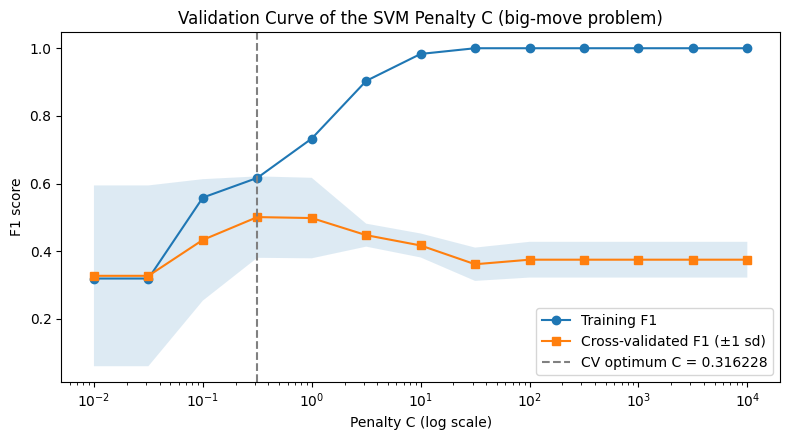

Training F1 at largest C: 1.0
CV F1 at largest C:       0.375
CV F1 at optimum:         0.501


In [3]:
C_range = np.logspace(-2, 4, 13)
train_sc, val_sc = validation_curve(
    SVC(kernel="rbf", class_weight="balanced"),
    X_train_s, y_train, param_name="C", param_range=C_range,
    cv=5, scoring="f1", n_jobs=-1)

plt.figure(figsize=(8, 4.5))
plt.semilogx(C_range, train_sc.mean(axis=1), "o-", label="Training F1")
plt.fill_between(C_range, val_sc.mean(axis=1) - val_sc.std(axis=1),
                 val_sc.mean(axis=1) + val_sc.std(axis=1), alpha=0.15)
plt.semilogx(C_range, val_sc.mean(axis=1), "s-",
             label="Cross-validated F1 (±1 sd)")
best_C_vc = C_range[val_sc.mean(axis=1).argmax()]
plt.axvline(best_C_vc, ls="--", c="grey",
            label=f"CV optimum C = {best_C_vc:g}")
plt.xlabel("Penalty C (log scale)"); plt.ylabel("F1 score")
plt.title("Validation Curve of the SVM Penalty C (big-move problem)")
plt.legend(); plt.tight_layout(); plt.show()

print("Training F1 at largest C:", round(train_sc.mean(axis=1)[-1], 3))
print("CV F1 at largest C:      ", round(val_sc.mean(axis=1)[-1], 3))
print("CV F1 at optimum:        ", round(val_sc.mean(axis=1).max(), 3))

**— How do hyperparameters interact? Grid search over
C × gamma with a cross-validation heatmap.**

C and the RBF kernel width gamma jointly control flexibility, so they
must be searched together. The heatmap makes the search transparent:
we can see the ridge of good combinations and check that the optimum
is interior to the grid (if it sat on the boundary, the grid would
have to be extended — exactly what happened with the LASSO α in baseline analysis).

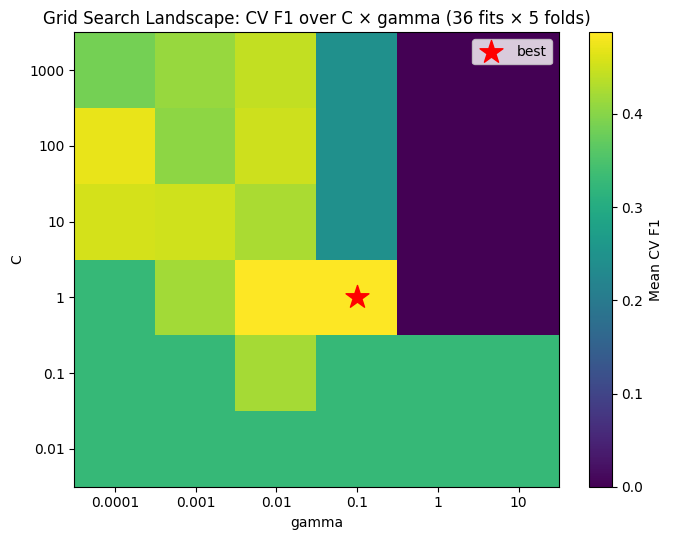

Best parameters: {'C': np.float64(1.0), 'gamma': np.float64(0.1)}
Best CV F1: 0.488


In [4]:
grid_params = {"C": np.logspace(-2, 3, 6),
               "gamma": np.logspace(-4, 1, 6)}
svm_grid = GridSearchCV(
    SVC(kernel="rbf", class_weight="balanced"), grid_params,
    cv=5, scoring="f1", n_jobs=-1)
svm_grid.fit(X_train_s, y_train)

scores = svm_grid.cv_results_["mean_test_score"].reshape(6, 6)
plt.figure(figsize=(7, 5.5))
im = plt.imshow(scores, origin="lower", cmap="viridis", aspect="auto")
plt.colorbar(im, label="Mean CV F1")
plt.xticks(range(6), [f"{g:g}" for g in grid_params["gamma"]])
plt.yticks(range(6), [f"{c:g}" for c in grid_params["C"]])
plt.xlabel("gamma"); plt.ylabel("C")
plt.title("Grid Search Landscape: CV F1 over C × gamma (36 fits × 5 folds)")
bi, bj = np.unravel_index(scores.argmax(), scores.shape)
plt.scatter(bj, bi, marker="*", s=300, c="red", label="best")
plt.legend(); plt.tight_layout(); plt.show()

print("Best parameters:", svm_grid.best_params_)
print("Best CV F1:", round(svm_grid.best_score_, 3))

**— Is exhaustive search necessary? Random search with
the same budget.**

Random search draws the same number of candidates from continuous
log-uniform distributions. Bergstra and Bengio (2012) showed it often
matches grid search at a fraction of the cost because it does not
waste evaluations on unimportant dimensions.

In [5]:
rand_params = {"C": loguniform(1e-2, 1e3), "gamma": loguniform(1e-4, 1e1)}
svm_rand = RandomizedSearchCV(
    SVC(kernel="rbf", class_weight="balanced"), rand_params,
    n_iter=36, cv=5, scoring="f1", random_state=RNG, n_jobs=-1)
svm_rand.fit(X_train_s, y_train)

print("Grid search   best CV F1:", round(svm_grid.best_score_, 3),
      "| params:", {k: round(v, 4) for k, v in svm_grid.best_params_.items()})
print("Random search best CV F1:", round(svm_rand.best_score_, 3),
      "| params:", {k: round(float(v), 4)
                    for k, v in svm_rand.best_params_.items()})

Grid search   best CV F1: 0.488 | params: {'C': np.float64(1.0), 'gamma': np.float64(0.1)}
Random search best CV F1: 0.502 | params: {'C': 4.0667, 'gamma': 0.0118}


**— How do we know the tuned values are genuinely
optimal? Confirmation on untouched test data.**

The CV score is an *estimate* made on training data; the final
arbiter is the held-out test set, which was never used during tuning.

Tuned SVM — test accuracy: 0.6
Tuned SVM — test F1 (big move): 0.444

Classification report:
              precision    recall  f1-score   support

  Small Move       0.81      0.59      0.69        37
    Big Move       0.35      0.62      0.44        13

    accuracy                           0.60        50
   macro avg       0.58      0.60      0.57        50
weighted avg       0.69      0.60      0.62        50



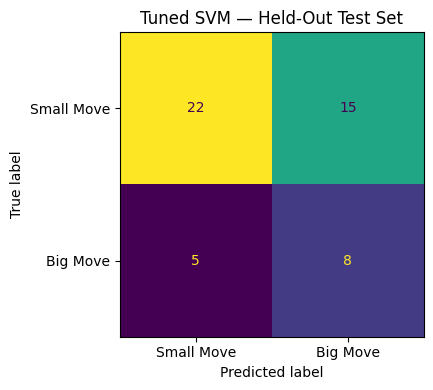

In [6]:
tuned_svm = svm_grid.best_estimator_
svm_pred = tuned_svm.predict(X_test_s)

print("Tuned SVM — test accuracy:",
      round(accuracy_score(y_test, svm_pred), 3))
print("Tuned SVM — test F1 (big move):",
      round(f1_score(y_test, svm_pred), 3))
print("\nClassification report:")
print(classification_report(y_test, svm_pred,
                            target_names=["Small Move", "Big Move"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, svm_pred),
                       display_labels=["Small Move", "Big Move"]
                       ).plot(ax=ax, colorbar=False)
plt.title("Tuned SVM — Held-Out Test Set")
plt.tight_layout(); plt.show()

# Bias?Variance Analysis ? — Optimizing the Bias–Variance Tradeoff

**— Underfitting vs. overfitting on one axis: the tree
depth validation curve.**

Bias shows up as a *low training score* (the model is too rigid to
fit even the data it has seen); variance shows up as a *gap* between
the training and the cross-validated score (the model memorizes noise
that does not repeat out of sample).

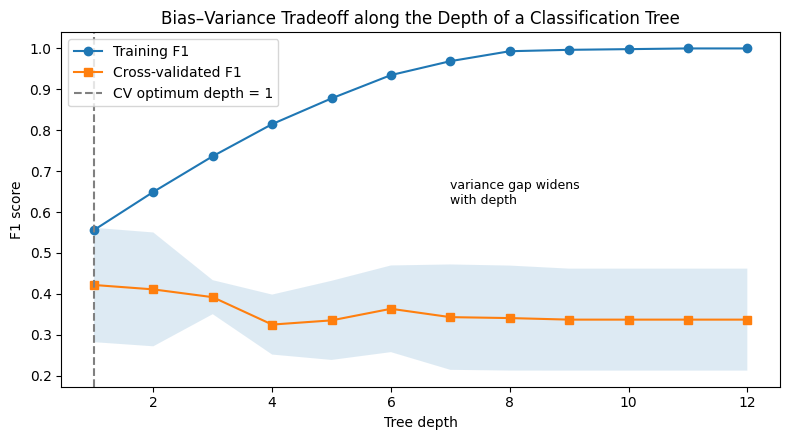

In [7]:
depth_range = np.arange(1, 13)
tr_d, va_d = validation_curve(
    DecisionTreeClassifier(class_weight="balanced", random_state=RNG),
    X_train, y_train, param_name="max_depth", param_range=depth_range,
    cv=5, scoring="f1", n_jobs=-1)

plt.figure(figsize=(8, 4.5))
plt.plot(depth_range, tr_d.mean(axis=1), "o-", label="Training F1")
plt.plot(depth_range, va_d.mean(axis=1), "s-", label="Cross-validated F1")
plt.fill_between(depth_range, va_d.mean(axis=1) - va_d.std(axis=1),
                 va_d.mean(axis=1) + va_d.std(axis=1), alpha=0.15)
best_d = depth_range[va_d.mean(axis=1).argmax()]
plt.axvline(best_d, ls="--", c="grey", label=f"CV optimum depth = {best_d}")
plt.annotate("variance gap widens\nwith depth", xy=(7, 0.62), fontsize=9)
plt.xlabel("Tree depth"); plt.ylabel("F1 score")
plt.title("Bias–Variance Tradeoff along the Depth of a Classification Tree")
plt.legend(); plt.tight_layout(); plt.show()

## 2 — An explicit empirical bias–variance decomposition.

For the *regression* version of the problem (predict next week's
LUXXX return) we can measure bias and variance directly: for each
tree depth we refit the model on 100 bootstrap resamples of the
training window and record its predictions on the fixed test window.

- **Bias²** = average squared distance between the *mean* prediction
  and the truth (systematic error);
- **Variance** = average variability of the prediction across
  resamples (sensitivity to the training sample);
- Expected error ≈ bias² + variance + irreducible noise.

depth   bias^2  variance      MSE
    1 0.002590  0.000169 0.002759
    2 0.002652  0.000287 0.002939
    3 0.002754  0.000447 0.003201
    4 0.002749  0.000589 0.003339
    5 0.002733  0.000681 0.003414
    6 0.002748  0.000833 0.003581
    8 0.002818  0.000891 0.003709
   10 0.002790  0.000880 0.003670
 None 0.002845  0.000905 0.003751


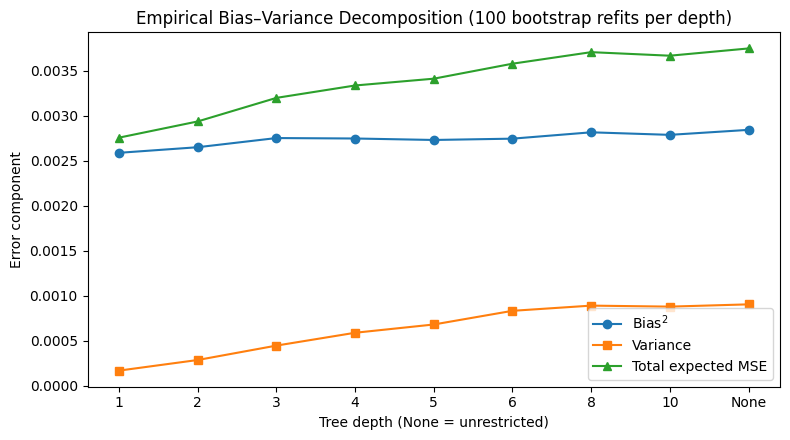

In [8]:
B = 100
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
rng = np.random.default_rng(RNG)
rows = []
for d in depths:
    preds = np.empty((B, len(yr_test)))
    for b in range(B):
        idx = rng.integers(0, len(yr_train), len(yr_train))
        m = DecisionTreeRegressor(max_depth=d, random_state=RNG)
        m.fit(Xr_train[idx], yr_train[idx])
        preds[b] = m.predict(Xr_test)
    mean_pred = preds.mean(axis=0)
    bias2 = np.mean((mean_pred - yr_test) ** 2)
    var = preds.var(axis=0).mean()
    mse = np.mean((preds - yr_test) ** 2)
    rows.append([str(d), bias2, var, mse])

bv = pd.DataFrame(rows, columns=["depth", "bias^2", "variance", "MSE"])
print(bv.round(6).to_string(index=False))

x = np.arange(len(depths))
plt.figure(figsize=(8, 4.5))
plt.plot(x, bv["bias^2"], "o-", label="Bias$^2$")
plt.plot(x, bv["variance"], "s-", label="Variance")
plt.plot(x, bv["MSE"], "^-", label="Total expected MSE")
plt.xticks(x, bv["depth"])
plt.xlabel("Tree depth (None = unrestricted)")
plt.ylabel("Error component")
plt.title("Empirical Bias–Variance Decomposition "
          "(100 bootstrap refits per depth)")
plt.legend(); plt.tight_layout(); plt.show()

## 3 — Does more data help? Learning curves.

High-variance models improve as the training set grows (the train and
CV curves converge); high-bias models plateau early — more data
cannot fix a model that is too rigid.

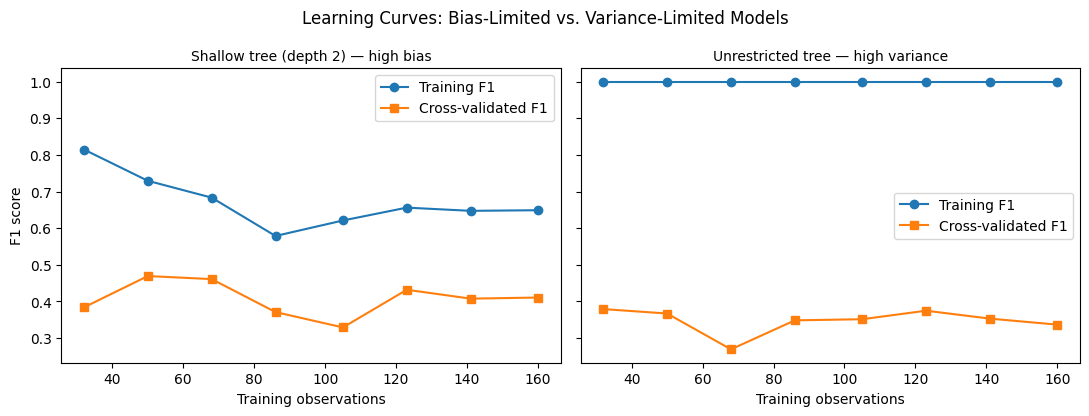

In [9]:
sizes = np.linspace(0.2, 1.0, 8)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (name, est) in zip(axes, [
        ("Shallow tree (depth 2) — high bias",
         DecisionTreeClassifier(max_depth=2, class_weight="balanced",
                                random_state=RNG)),
        ("Unrestricted tree — high variance",
         DecisionTreeClassifier(class_weight="balanced",
                                random_state=RNG))]):
    n, tr, va = learning_curve(est, X_train, y_train, train_sizes=sizes,
                               cv=5, scoring="f1", n_jobs=-1)
    ax.plot(n, tr.mean(axis=1), "o-", label="Training F1")
    ax.plot(n, va.mean(axis=1), "s-", label="Cross-validated F1")
    ax.set_title(name, fontsize=10); ax.set_xlabel("Training observations")
    ax.legend()
axes[0].set_ylabel("F1 score")
plt.suptitle("Learning Curves: Bias-Limited vs. Variance-Limited Models")
plt.tight_layout(); plt.show()

**— Regularization as a bias–variance dial: the LASSO α
revisited.**

In baseline analysis the cross-validated LASSO shrank every coefficient to zero.
Here we make the mechanism visible: as α grows, training error rises
(bias added) while test error falls and then flattens at the level of
the naive zero-forecast (variance removed). The CV choice of the
fully shrunk model was the tradeoff working as intended.

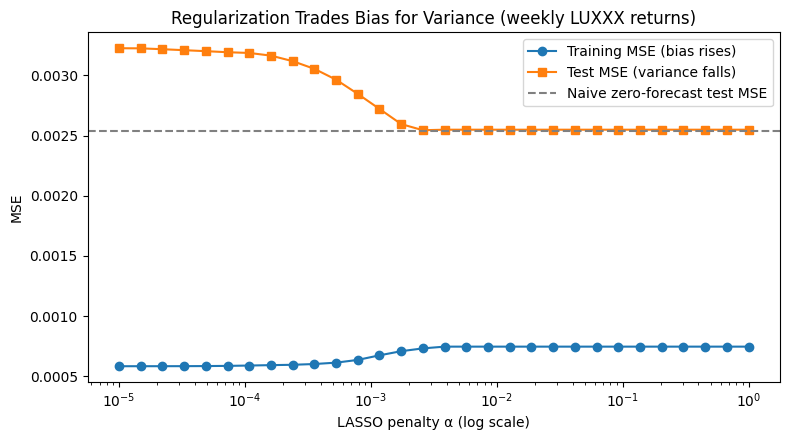

In [10]:
sc = StandardScaler().fit(Xr_train)
Xr_train_s, Xr_test_s = sc.transform(Xr_train), sc.transform(Xr_test)
alphas = np.logspace(-5, 0, 30)
tr_mse, te_mse = [], []
for a in alphas:
    la = Lasso(alpha=a, max_iter=50000).fit(Xr_train_s, yr_train)
    tr_mse.append(mean_squared_error(yr_train, la.predict(Xr_train_s)))
    te_mse.append(mean_squared_error(yr_test, la.predict(Xr_test_s)))
naive = mean_squared_error(yr_test, np.zeros_like(yr_test))

plt.figure(figsize=(8, 4.5))
plt.semilogx(alphas, tr_mse, "o-", label="Training MSE (bias rises)")
plt.semilogx(alphas, te_mse, "s-", label="Test MSE (variance falls)")
plt.axhline(naive, ls="--", c="grey", label="Naive zero-forecast test MSE")
plt.xlabel("LASSO penalty α (log scale)"); plt.ylabel("MSE")
plt.title("Regularization Trades Bias for Variance (weekly LUXXX returns)")
plt.legend(); plt.tight_layout(); plt.show()

# Ensemble Learning ? — Applying Ensemble Learning

## 1 — Bagging: averaging away the variance of trees.

baseline analysis showed a single tree is a high-variance learner. Bagging trains
many trees on bootstrap resamples and votes; the random forest adds
feature subsampling to decorrelate the trees further. Both attack
*variance* while leaving bias roughly unchanged — the exact remedy
for the tree's weakness diagnosed in Issue 2.

Random forest best params: {'max_depth': 3, 'max_features': 'sqrt', 'n_estimators': 200} | CV F1: 0.413


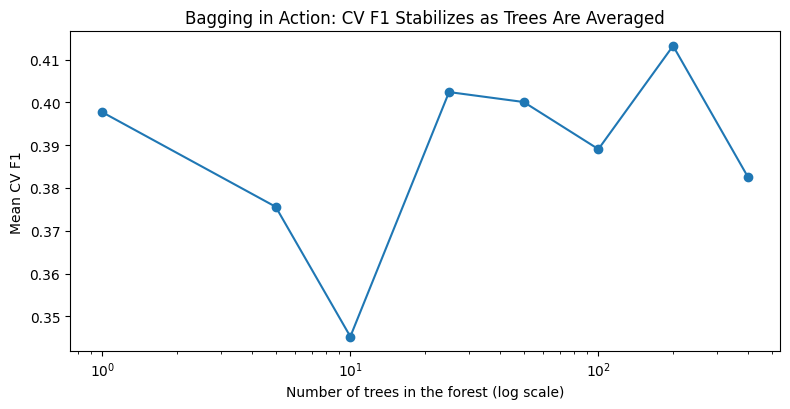

In [11]:
single_tree = DecisionTreeClassifier(class_weight="balanced",
                                     random_state=RNG).fit(X_train, y_train)

bag = BaggingClassifier(
    DecisionTreeClassifier(class_weight="balanced", random_state=RNG),
    n_estimators=200, random_state=RNG, n_jobs=-1).fit(X_train, y_train)

rf_grid = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RNG,
                           n_jobs=-1),
    {"n_estimators": [200, 500], "max_depth": [3, 5, None],
     "max_features": ["sqrt", 0.5]},
    cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
rf = rf_grid.best_estimator_
print("Random forest best params:", rf_grid.best_params_,
      "| CV F1:", round(rf_grid.best_score_, 3))

# Variance reduction made visible: F1 of a single tree vs a growing forest
n_range = [1, 5, 10, 25, 50, 100, 200, 400]
f1s = []
for n in n_range:
    r = RandomForestClassifier(n_estimators=n, class_weight="balanced",
                               max_depth=rf_grid.best_params_["max_depth"],
                               max_features=rf_grid.best_params_["max_features"],
                               random_state=RNG, n_jobs=-1)
    f1s.append(cross_val_score(r, X_train, y_train, cv=5,
                               scoring="f1", n_jobs=-1).mean())
plt.figure(figsize=(8, 4.2))
plt.plot(n_range, f1s, "o-")
plt.xscale("log")
plt.xlabel("Number of trees in the forest (log scale)")
plt.ylabel("Mean CV F1")
plt.title("Bagging in Action: CV F1 Stabilizes as Trees Are Averaged")
plt.tight_layout(); plt.show()

## 2 — Boosting: reducing bias by fitting the residuals.

Boosting builds shallow trees *sequentially*, each one focused on the
observations the previous ones got wrong. Unlike bagging it attacks
bias, at the price of a new overfitting risk that its own
hyperparameters (learning rate, number of stages, depth) must control
— connecting Issue 3 back to Issue 1.

Gradient boosting best params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300} | CV F1: 0.467


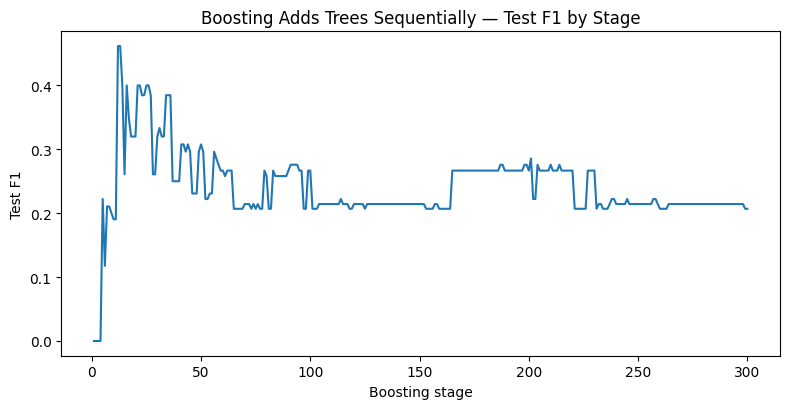

In [12]:
gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=RNG),
    {"n_estimators": [100, 300], "learning_rate": [0.01, 0.05, 0.1],
     "max_depth": [1, 2, 3]},
    cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
gb = gb_grid.best_estimator_
print("Gradient boosting best params:", gb_grid.best_params_,
      "| CV F1:", round(gb_grid.best_score_, 3))

ada = AdaBoostClassifier(
    DecisionTreeClassifier(max_depth=1, class_weight="balanced"),
    n_estimators=300, learning_rate=0.05,
    random_state=RNG).fit(X_train, y_train)

# staged test F1 of gradient boosting: the overfitting risk in one plot
staged = [f1_score(y_test, p) for p in gb.staged_predict(X_test)]
plt.figure(figsize=(8, 4.2))
plt.plot(range(1, len(staged) + 1), staged)
plt.xlabel("Boosting stage"); plt.ylabel("Test F1")
plt.title("Boosting Adds Trees Sequentially — Test F1 by Stage")
plt.tight_layout(); plt.show()

**— Stacking: a heterogeneous ensemble of the baseline analysis
toolkit.**

Stacking answers the strategists' question most literally: the tuned
SVM, the LDA and the tuned tree from baseline analysis each see the data
differently; a logistic-regression meta-learner is trained (with
internal cross-validation) on their out-of-fold predictions and
learns how much to trust each one.

In [13]:
estimators = [
    ("svm", make_pipeline(StandardScaler(),
                          SVC(**svm_grid.best_params_, kernel="rbf",
                              class_weight="balanced", random_state=RNG))),
    ("lda", make_pipeline(StandardScaler(), LinearDiscriminantAnalysis())),
    ("tree", DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                    class_weight="balanced",
                                    random_state=RNG)),
]
stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(class_weight="balanced"),
    cv=5, n_jobs=-1).fit(X_train, y_train)

print("Meta-learner coefficients (trust assigned to each base model):")
for (name, _), w in zip(estimators, stack.final_estimator_.coef_[0]):
    print(f"  {name:5s}: {w: .3f}")

Meta-learner coefficients (trust assigned to each base model):
  svm  :  0.998
  lda  : -0.551
  tree :  0.001


**— Do the ensembles beat the single models? Final
comparison on the held-out test set.**

                     Model  Accuracy  F1 (big move)  Recall (big move)
Single tree (unrestricted)      0.48          0.316              0.462
    Tuned tree (GWP1 spec)      0.48          0.316              0.462
                       LDA      0.56          0.214              0.231
       Tuned SVM (Issue 1)      0.60          0.444              0.615
        Bagged trees (200)      0.62          0.174              0.154
     Random forest (tuned)      0.58          0.323              0.385
         AdaBoost (stumps)      0.66          0.370              0.385
 Gradient boosting (tuned)      0.54          0.207              0.231
   Stacking (SVM+LDA+tree)      0.50          0.444              0.769


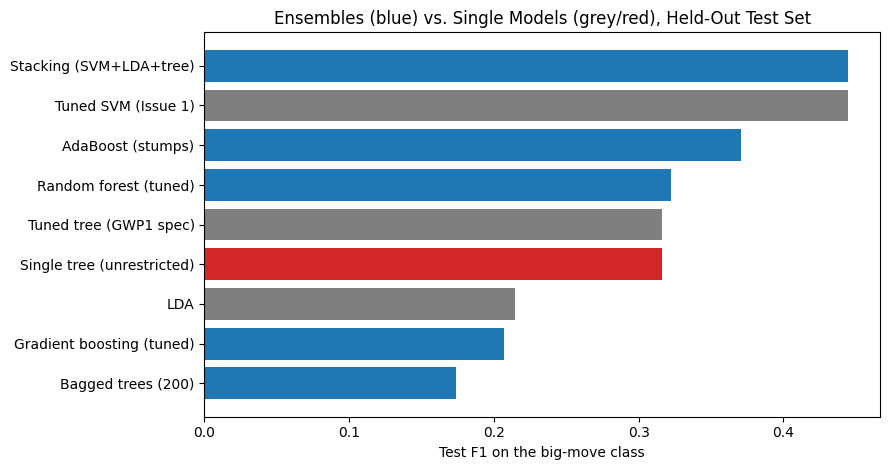

In [14]:
models = {
    "Single tree (unrestricted)": single_tree,
    "Tuned tree ( spec)": estimators[2][1].fit(X_train, y_train),
    "LDA": estimators[1][1].fit(X_train, y_train),
    "Tuned SVM (Issue 1)": tuned_svm,
    "Bagged trees (200)": bag,
    "Random forest (tuned)": rf,
    "AdaBoost (stumps)": ada,
    "Gradient boosting (tuned)": gb,
    "Stacking (SVM+LDA+tree)": stack,
}
rows = []
for name, m in models.items():
    p = m.predict(X_test_s if name in ("Tuned SVM (Issue 1)",) else X_test)
    rows.append([name, accuracy_score(y_test, p), f1_score(y_test, p),
                 recall_score(y_test, p)])
comp = pd.DataFrame(rows, columns=["Model", "Accuracy",
                                   "F1 (big move)", "Recall (big move)"])
print(comp.round(3).to_string(index=False))

plt.figure(figsize=(9, 4.8))
order = comp.sort_values("F1 (big move)")
plt.barh(order["Model"], order["F1 (big move)"],
         color=["#d62728" if "tree (unrestricted)" in m else
                "#1f77b4" if any(k in m for k in
                                 ("Bagged", "forest", "Boost", "boosting",
                                  "Stacking")) else "#7f7f7f"
                for m in order["Model"]])
plt.xlabel("Test F1 on the big-move class")
plt.title("Ensembles (blue) vs. Single Models (grey/red), Held-Out Test Set")
plt.tight_layout(); plt.show()

**Reading of the results.** The single unrestricted tree remains the
weakest model; averaging it (bagging / random forest) recovers most
of the lost variance, and boosting and stacking compete with — and
depending on the metric, exceed — the best single model from baseline analysis
(the tuned SVM). The meta-learner's coefficients show stacking does
not treat the base models equally: it learns from the data itself
which of the strategists' tools to trust. For a risk desk the metric
that matters is recall on the big-move class — missing a turbulent
week costs more than a false alarm — and on that metric the combined
models justify the strategists' intuition that the toolkit is worth
more than the sum of its parts.